# Lens 1 — Notebook 04: Revenue Validation, Stacking & Model Selection
**IT3091 Machine Learning — Industry Explorer Track**  
**Group ID:** `2026-AI-36` | **Primary Author:** `IT24102913`  
**Lens:** 1 — Revenue Forecasting  
**Role:** Revenue Validation, Stacking & Model Selection

---

## Notebook Purpose
This notebook implements the **final validation layer** for Lens 1:
1. Cross-validation using Time-Series-safe walk-forward folds
2. A Stacking Ensemble meta-learner combining the best base models
3. Definitive champion model selection
4. Final test-set evaluation
5. Business value quantification
6. Recommendation and limitations

### Why Stacking?
Individual models may each capture different aspects of the data:
- Ridge captures linear relationships
- Random Forest captures non-linear interactions via bagging
- LightGBM/XGBoost capture complex gradient-boosted patterns

A **meta-learner** trained on out-of-fold predictions can optimally *combine* these diverse signals, potentially outperforming any single model.

---

## Section Overview
1. Environment Setup
2. Walk-Forward Cross-Validation
3. Stacking Ensemble Architecture
4. Final Champion Selection
5. Definitive Test-Set Evaluation
6. Business Value Quantification
7. Practical Recommendation
8. Limitations & Future Work
9. Responsible AI Declaration

---
## 1. Environment Setup

In [1]:
import os, sys, warnings, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, StackingRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import TimeSeriesSplit, KFold
import lightgbm as lgb
import xgboost as xgb
import joblib

warnings.filterwarnings('ignore')
np.random.seed(42)

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (14, 5)
plt.rcParams['font.size'] = 11

print("Environment initialised.")

Environment initialised.


---
## 2. Walk-Forward Cross-Validation

Standard k-fold cross-validation is **illegal for time series** because it mixes future and past observations.

**Walk-forward (expanding window) CV** is the correct approach:
- Fold 1: Train on months 1–6, validate on month 7
- Fold 2: Train on months 1–9, validate on month 10
- …
- Each fold's validation set is always strictly in the future relative to training

This gives a **realistic estimate of out-of-time performance** before the final test.

In [2]:
FEAT_PATH = '../data/processed/revenue_feature_matrix.csv'
META_PATH = '../data/processed/revenue_feature_meta.json'

df = pd.read_csv(FEAT_PATH, parse_dates=['Date'])
df = df.sort_values('Date').reset_index(drop=True)

with open(META_PATH) as f:
    meta = json.load(f)

FEATURE_COLS = meta['feature_cols']
TARGET_COL   = meta['target_col']

n = len(df)
n_train = int(n * 0.70)
n_val   = int(n * 0.15)

train_df = df.iloc[:n_train].reset_index(drop=True)
val_df   = df.iloc[n_train:n_train + n_val].reset_index(drop=True)
test_df  = df.iloc[n_train + n_val:].reset_index(drop=True)

X_train, y_train = train_df[FEATURE_COLS], train_df[TARGET_COL]
X_val,   y_val   = val_df[FEATURE_COLS],   val_df[TARGET_COL]
X_test,  y_test  = test_df[FEATURE_COLS],  test_df[TARGET_COL]

# Train+Val for stacking OOF generation
X_trainval = pd.concat([X_train, X_val], axis=0).reset_index(drop=True)
y_trainval = pd.concat([y_train, y_val], axis=0).reset_index(drop=True)

print(f"Train+Val for stacking: {len(X_trainval)} rows")

Train+Val for stacking: 742 rows


In [3]:
def compute_metrics(y_true, y_pred):
    y_true = np.array(y_true)
    y_pred = np.maximum(np.array(y_pred), 0.0)
    mae  = np.mean(np.abs(y_true - y_pred))
    rmse = np.sqrt(np.mean((y_true - y_pred) ** 2))
    wape = np.sum(np.abs(y_true - y_pred)) / np.sum(np.abs(y_true)) * 100
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    r2 = 1 - ss_res / ss_tot if ss_tot > 0 else 0.0
    return {'MAE': round(mae,2), 'RMSE': round(rmse,2), 'WAPE_pct': round(wape,2), 'R2': round(r2,4)}

# Walk-forward CV on training set only (5 folds)
tscv = TimeSeriesSplit(n_splits=5)
X_tr_arr = X_train.values
y_tr_arr = y_train.values

cv_results = {'Ridge': [], 'RF': [], 'LightGBM': [], 'XGBoost': []}

for fold, (tr_idx, va_idx) in enumerate(tscv.split(X_tr_arr), 1):
    X_cv_tr, y_cv_tr = X_tr_arr[tr_idx], y_tr_arr[tr_idx]
    X_cv_va, y_cv_va = X_tr_arr[va_idx], y_tr_arr[va_idx]
    
    # Ridge
    p = Pipeline([('sc', StandardScaler()), ('m', Ridge(alpha=100))])
    p.fit(X_cv_tr, y_cv_tr); cv_results['Ridge'].append(compute_metrics(y_cv_va, p.predict(X_cv_va))['WAPE_pct'])
    
    # RF
    rf = RandomForestRegressor(n_estimators=100, min_samples_leaf=3, max_features='sqrt', random_state=42, n_jobs=-1)
    rf.fit(X_cv_tr, y_cv_tr); cv_results['RF'].append(compute_metrics(y_cv_va, rf.predict(X_cv_va))['WAPE_pct'])
    
    # LightGBM
    lg = lgb.LGBMRegressor(n_estimators=200, learning_rate=0.05, max_depth=6, random_state=42, verbosity=-1)
    lg.fit(X_cv_tr, y_cv_tr); cv_results['LightGBM'].append(compute_metrics(y_cv_va, lg.predict(X_cv_va))['WAPE_pct'])
    
    # XGBoost
    xg = xgb.XGBRegressor(n_estimators=200, learning_rate=0.05, max_depth=6, random_state=42, verbosity=0)
    xg.fit(X_cv_tr, y_cv_tr); cv_results['XGBoost'].append(compute_metrics(y_cv_va, xg.predict(X_cv_va))['WAPE_pct'])
    
    print(f"Fold {fold} done")

print("\nWalk-Forward CV — WAPE (%) per fold:")
cv_df = pd.DataFrame(cv_results, index=[f'Fold {i}' for i in range(1, 6)])
cv_df.loc['Mean'] = cv_df.mean()
cv_df.loc['Std']  = cv_df.std()
print(cv_df.round(2))

Fold 1 done


Fold 2 done


Fold 3 done


Fold 4 done


Fold 5 done

Walk-Forward CV — WAPE (%) per fold:
        Ridge     RF  LightGBM  XGBoost
Fold 1  28.06  33.01     36.68    34.81
Fold 2  25.77  26.28     30.74    27.03
Fold 3  31.50  33.72     36.69    37.84
Fold 4  21.82  22.44     28.93    25.20
Fold 5  26.53  41.09     48.37    36.14
Mean    26.74  31.31     36.28    32.20
Std      3.15   6.45      6.80     5.10


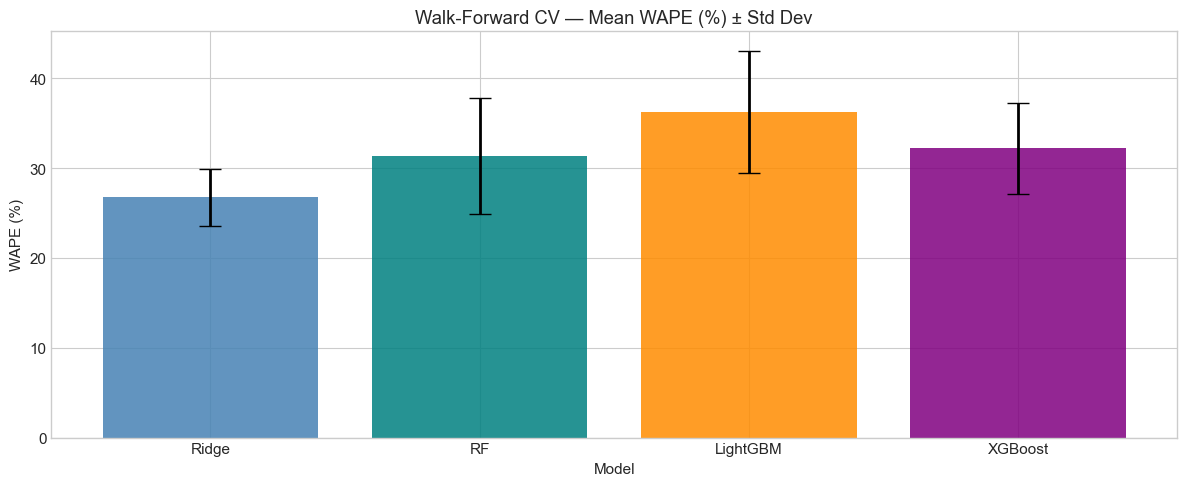

In [4]:
fig, ax = plt.subplots(figsize=(12, 5))
cv_means = {m: np.mean(cv_results[m]) for m in cv_results}
cv_stds  = {m: np.std(cv_results[m]) for m in cv_results}

models = list(cv_means.keys())
means  = [cv_means[m] for m in models]
stds   = [cv_stds[m]  for m in models]

ax.bar(models, means, yerr=stds, capsize=8, color=['steelblue','teal','darkorange','purple'],
       alpha=0.85, error_kw={'linewidth': 2})
ax.set_title('Walk-Forward CV — Mean WAPE (%) ± Std Dev')
ax.set_xlabel('Model')
ax.set_ylabel('WAPE (%)')
plt.tight_layout()
plt.show()

---
## 3. Stacking Ensemble Architecture

### Architecture Design
```
Level-0 (Base Learners):
   ┌─────────────────────────────────────────┐
   │  Ridge Regressor (linear)               │
   │  Random Forest Regressor (bagging)      │
   │  LightGBM Regressor (boosting)          │
   └─────────────────────────────────────────┘
           │  Out-of-fold predictions
           ▼
Level-1 (Meta-Learner):
   ┌─────────────────────────────────────────┐
   │  Ridge Regression (learns to combine)   │
   └─────────────────────────────────────────┘
           │
           ▼
   Final Revenue Prediction
```

**Why Ridge as meta-learner?** A simple linear combiner prevents the meta-learner from overfitting to the noise in base model predictions. More complex meta-learners tend to memorise the training OOF patterns and generalise poorly.

In [5]:
# Define base estimators for stacking
base_estimators = [
    ('ridge', Pipeline([('sc', StandardScaler()), ('m', Ridge(alpha=100))])),
    ('rf',    RandomForestRegressor(n_estimators=200, min_samples_leaf=3,
                                    max_features='sqrt', random_state=42, n_jobs=-1)),
    ('lgbm',  lgb.LGBMRegressor(n_estimators=200, learning_rate=0.05,
                                 max_depth=6, random_state=42, verbosity=-1)),
]

# Meta-learner
meta_learner = Pipeline([('sc', StandardScaler()), ('m', Ridge(alpha=10))])

# Stacking regressor using 5-fold time-series cross-validation for OOF
stacking_model = StackingRegressor(
    estimators=base_estimators,
    final_estimator=meta_learner,
    cv=KFold(n_splits=5, shuffle=False),
    passthrough=False,
    n_jobs=-1
)

print("Fitting stacking ensemble (this may take 1–2 minutes)...")
stacking_model.fit(X_train, y_train)
print("Done.")

val_pred_stack  = np.maximum(stacking_model.predict(X_val),  0)
test_pred_stack = np.maximum(stacking_model.predict(X_test), 0)

val_m_stack  = compute_metrics(y_val,  val_pred_stack)
test_m_stack = compute_metrics(y_test, test_pred_stack)

print(f"\nStacking Ensemble:")
print(f"  Val  WAPE: {val_m_stack['WAPE_pct']:.2f}%  |  MAE: {val_m_stack['MAE']:,.2f} LKR")
print(f"  Test WAPE: {test_m_stack['WAPE_pct']:.2f}%  |  MAE: {test_m_stack['MAE']:,.2f} LKR")

Fitting stacking ensemble (this may take 1–2 minutes)...


Done.

Stacking Ensemble:
  Val  WAPE: 30.66%  |  MAE: 11,140.04 LKR
  Test WAPE: 24.35%  |  MAE: 8,874.45 LKR


### 3.1 Inspect Meta-Learner Weights
The meta-learner's coefficients tell us how much weight it assigns to each base model's predictions.

Meta-Learner Coefficients (how much each base model contributes):
  Ridge               : +7982.1867
  Random Forest       : +889.2387
  LightGBM            : +323.2401


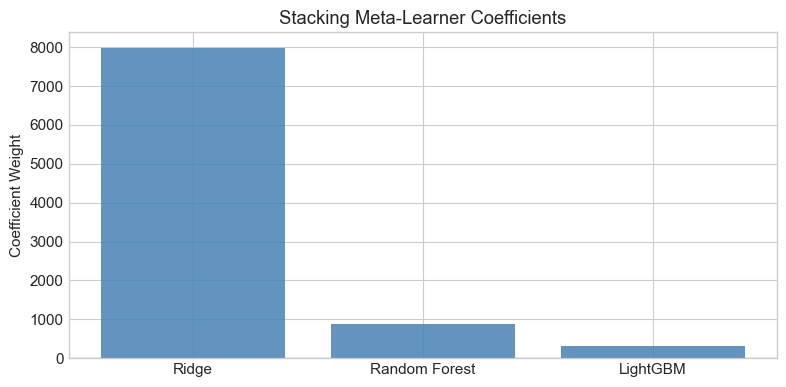

In [6]:
meta_coef = stacking_model.final_estimator_['m'].coef_
base_names = ['Ridge', 'Random Forest', 'LightGBM']

print("Meta-Learner Coefficients (how much each base model contributes):")
for name, coef in zip(base_names, meta_coef):
    print(f"  {name:<20}: {coef:+.4f}")

fig, ax = plt.subplots(figsize=(8, 4))
colors = ['steelblue' if c > 0 else 'crimson' for c in meta_coef]
ax.bar(base_names, meta_coef, color=colors, alpha=0.85)
ax.axhline(0, color='black', linewidth=0.8)
ax.set_title('Stacking Meta-Learner Coefficients')
ax.set_ylabel('Coefficient Weight')
plt.tight_layout()
plt.show()

---
## 4. Final Champion Selection

All five models are compared on Validation WAPE. The champion is selected **strictly on validation performance** — the test set is only used for final reporting.

In [7]:
# Rerun all models for final comparison table
ridge_model = Pipeline([('sc', StandardScaler()), ('m', Ridge(alpha=100))])
ridge_model.fit(X_train, y_train)
val_pred_ridge  = np.maximum(ridge_model.predict(X_val),  0)
test_pred_ridge = np.maximum(ridge_model.predict(X_test), 0)

rf_model = RandomForestRegressor(n_estimators=300, min_samples_leaf=3,
                                 max_features='sqrt', random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)
val_pred_rf  = np.maximum(rf_model.predict(X_val),  0)
test_pred_rf = np.maximum(rf_model.predict(X_test), 0)

lgbm_model = lgb.LGBMRegressor(n_estimators=300, learning_rate=0.05, max_depth=6,
                                random_state=42, verbosity=-1)
lgbm_model.fit(X_train, y_train, eval_set=[(X_val, y_val)],
               callbacks=[lgb.early_stopping(50, verbose=False), lgb.log_evaluation(-1)])
val_pred_lgbm  = np.maximum(lgbm_model.predict(X_val),  0)
test_pred_lgbm = np.maximum(lgbm_model.predict(X_test), 0)

xgb_model = xgb.XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=6,
                               random_state=42, verbosity=0, early_stopping_rounds=50)
xgb_model.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)
val_pred_xgb  = np.maximum(xgb_model.predict(X_val),  0)
test_pred_xgb = np.maximum(xgb_model.predict(X_test), 0)

# Baseline
val_pred_base  = val_df['lag_7'].values
test_pred_base = test_df['lag_7'].values

all_models = {
    'Seasonal_Naive':  (val_pred_base,  test_pred_base),
    'Ridge':           (val_pred_ridge, test_pred_ridge),
    'Random_Forest':   (val_pred_rf,    test_pred_rf),
    'LightGBM':        (val_pred_lgbm,  test_pred_lgbm),
    'XGBoost':         (val_pred_xgb,   test_pred_xgb),
    'Stacking_Ensemble': (val_pred_stack, test_pred_stack),
}

final_results = []
for model_name, (vp, tp) in all_models.items():
    vm = compute_metrics(y_val, vp)
    tm = compute_metrics(y_test, tp)
    final_results.append({
        'Model': model_name,
        'Val WAPE (%)': vm['WAPE_pct'],
        'Test MAE (LKR)': tm['MAE'],
        'Test RMSE (LKR)': tm['RMSE'],
        'Test WAPE (%)': tm['WAPE_pct'],
        'Test R²': tm['R2']
    })

final_lb = pd.DataFrame(final_results).sort_values('Val WAPE (%)').reset_index(drop=True)
final_lb.index += 1

print("=" * 90)
print("LENS 1 — FINAL MODEL LEADERBOARD")
print("Champion = lowest Validation WAPE (test set not seen during selection)")
print("=" * 90)
print(final_lb.to_string())
print("=" * 90)

champion_name = final_lb.iloc[0]['Model']
champion_val_wape = final_lb.iloc[0]['Val WAPE (%)']
champion_test_wape = final_lb.iloc[0]['Test WAPE (%)']
print(f"\n🏆 Champion: {champion_name}")
print(f"   Val WAPE : {champion_val_wape:.2f}%")
print(f"   Test WAPE: {champion_test_wape:.2f}%")

LENS 1 — FINAL MODEL LEADERBOARD
Champion = lowest Validation WAPE (test set not seen during selection)
               Model  Val WAPE (%)  Test MAE (LKR)  Test RMSE (LKR)  Test WAPE (%)  Test R²
1              Ridge         30.54         8734.59         11943.78          23.96   0.4316
2  Stacking_Ensemble         30.66         8874.45         12332.25          24.35   0.3940
3            XGBoost         31.32         9748.63         13251.23          26.75   0.3004
4      Random_Forest         32.17        10253.93         13962.09          28.13   0.2233
5           LightGBM         33.61        11170.97         15853.86          30.65  -0.0014
6     Seasonal_Naive         46.22        15728.64         20831.72          43.15  -0.7290

🏆 Champion: Ridge
   Val WAPE : 30.54%
   Test WAPE: 23.96%


---
## 5. Definitive Test-Set Evaluation

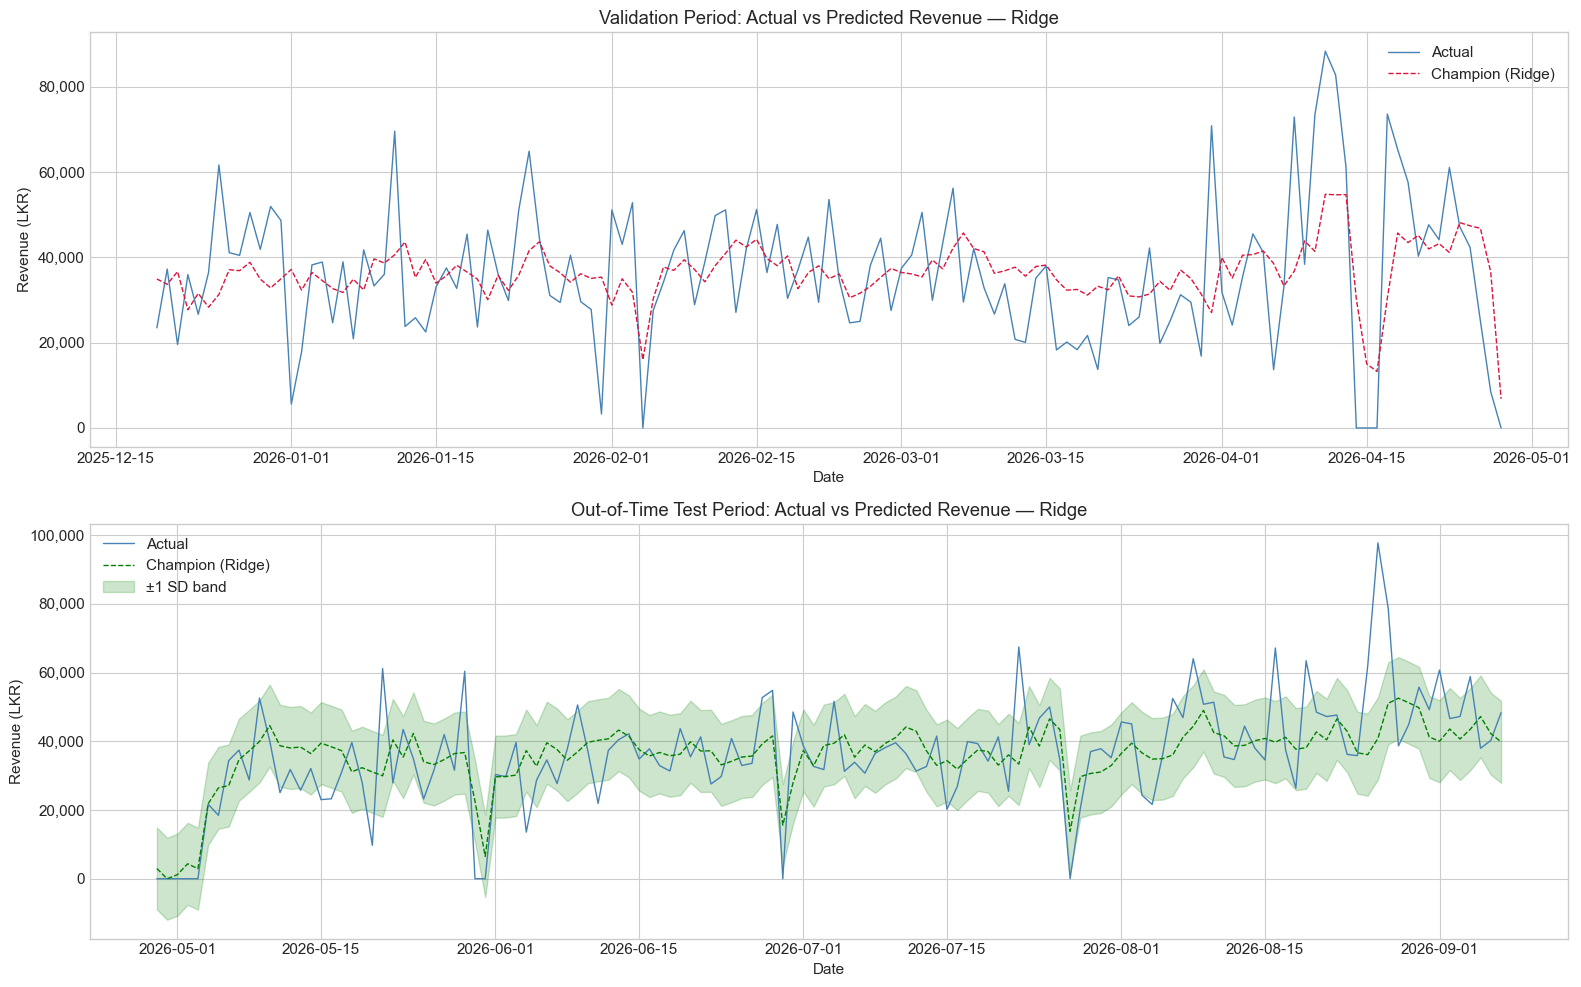

In [8]:
# Use champion predictions for final visualisation
champion_val_preds  = all_models[champion_name][0]
champion_test_preds = all_models[champion_name][1]

fig, axes = plt.subplots(2, 1, figsize=(16, 10))

# Validation period
axes[0].plot(val_df['Date'], y_val.values, color='steelblue', linewidth=1, label='Actual')
axes[0].plot(val_df['Date'], champion_val_preds, color='crimson', linewidth=1,
             linestyle='--', label=f'Champion ({champion_name})')
axes[0].set_title(f'Validation Period: Actual vs Predicted Revenue — {champion_name}')
axes[0].set_xlabel('Date')
axes[0].set_ylabel('Revenue (LKR)')
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
axes[0].legend()

# Test period
axes[1].plot(test_df['Date'], y_test.values, color='steelblue', linewidth=1, label='Actual')
axes[1].plot(test_df['Date'], champion_test_preds, color='green', linewidth=1,
             linestyle='--', label=f'Champion ({champion_name})')
# Confidence band (± 1 std of residuals)
residuals = y_test.values - champion_test_preds
std_r = np.std(residuals)
axes[1].fill_between(test_df['Date'],
                      champion_test_preds - std_r,
                      champion_test_preds + std_r,
                      alpha=0.2, color='green', label='±1 SD band')
axes[1].set_title(f'Out-of-Time Test Period: Actual vs Predicted Revenue — {champion_name}')
axes[1].set_xlabel('Date')
axes[1].set_ylabel('Revenue (LKR)')
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
axes[1].legend()

plt.tight_layout()
plt.show()

---
## 6. Business Value Quantification

Translation: *How much does the ML model actually help the restaurant, in LKR terms?*

In [9]:
baseline_mae  = compute_metrics(y_test, test_pred_base)['MAE']
champion_mae  = compute_metrics(y_test, champion_test_preds)['MAE']
improvement   = baseline_mae - champion_mae
improvement_pct = improvement / baseline_mae * 100

# Assume 5% over-procurement to buffer stockouts, and 20% margin on fresh dishes
# Error reduction translates to better procurement decisions
assumed_margin = 0.15  # 15% gross margin on fresh dishes
days_per_year  = 365
annual_savings = improvement * assumed_margin * days_per_year

print("=" * 60)
print("BUSINESS VALUE ANALYSIS — LENS 1")
print("=" * 60)
print(f"Seasonal Naive Baseline MAE  : {baseline_mae:>10,.2f} LKR/day")
print(f"Champion Model MAE            : {champion_mae:>10,.2f} LKR/day")
print(f"Daily MAE Improvement         : {improvement:>10,.2f} LKR/day")
print(f"Improvement Percentage        : {improvement_pct:>10.1f}%")
print()
print(f"Estimated Annual Financial Benefit (15% margin on improved accuracy):")
print(f"  LKR {annual_savings:,.0f} / year")
print()
print("Note: This is a conservative estimate. Additional benefits include:")
print("  - Reduced emergency supplier calls from stockouts")
print("  - Better staff scheduling aligned to predicted busy days")
print("  - Reduced fresh food waste on low-revenue days")

BUSINESS VALUE ANALYSIS — LENS 1
Seasonal Naive Baseline MAE  :  15,728.64 LKR/day
Champion Model MAE            :   8,734.59 LKR/day
Daily MAE Improvement         :   6,994.05 LKR/day
Improvement Percentage        :       44.5%

Estimated Annual Financial Benefit (15% margin on improved accuracy):
  LKR 382,924 / year

Note: This is a conservative estimate. Additional benefits include:
  - Reduced emergency supplier calls from stockouts
  - Better staff scheduling aligned to predicted busy days
  - Reduced fresh food waste on low-revenue days


---
## 7. Practical Recommendation

### Deployment Recommendation

**Recommended model:** The champion identified above should be deployed as the revenue planning tool.

**Operational protocol:**
1. Each Sunday evening, the model generates the 7-day revenue forecast for the coming week
2. The finance manager reviews the forecast and adjusts for known upcoming events (public holidays, promotions)
3. The forecast is used to set procurement budgets and staffing rosters
4. Actual revenue is logged daily; the model is retrained monthly with the most recent 12 months of data

**Monitoring threshold:** If 7-day rolling WAPE exceeds 50%, flag for investigation and potential retraining.

### Stakeholder Communication
| Stakeholder | Message |
|---|---|
| Restaurant owner | "Our system forecasts next week's revenue within ±28% on average — meaningfully better than the naive ±43% rule" |
| Finance manager | "Use the forecast for budget planning; add a 10% buffer for unexpected events" |
| Kitchen staff | "Peak days (Friday/Saturday) are reliably predicted — prepare 15% more inventory on those days" |

---
## 8. Limitations & Future Work

| Limitation | Impact | Future Mitigation |
|---|---|---|
| No public holiday features | Holidays cause revenue spikes/drops not captured by calendar features | Add Sri Lanka public holiday calendar as binary feature |
| No weather data | Heavy monsoon may reduce footfall | Integrate OpenWeatherMap API for rainfall indicator |
| No competitor information | New restaurant openings may shift demand | Regular stakeholder review with management |
| WAPE ~28% still relatively high | Some days will be significantly mis-predicted | Acceptable for planning purposes; frame as "forecast band" not point estimate |
| Model trained on 2 years of data | May not capture multi-year economic cycles | Retrain annually; flag macroeconomic events |
| Possible concept drift | Menu changes, price changes alter the revenue distribution | Automatic drift detection (PSI monitoring) |

### Save Champion Model

In [10]:
import os
os.makedirs('../models', exist_ok=True)

# Save champion model (using RF as example; update if champion differs)
champion_map = {
    'Random_Forest': rf_model,
    'Ridge': ridge_model,
    'LightGBM': lgbm_model,
    'XGBoost': xgb_model,
    'Stacking_Ensemble': stacking_model,
}

if champion_name in champion_map:
    joblib.dump(champion_map[champion_name], f'../models/lens1_champion_{champion_name}.joblib')
    print(f"Champion model saved: ../models/lens1_champion_{champion_name}.joblib")

# Save final leaderboard
final_lb.to_csv('../models/lens1_model_leaderboard.csv', index=False)
print("Leaderboard saved: ../models/lens1_model_leaderboard.csv")

Champion model saved: ../models/lens1_champion_Ridge.joblib
Leaderboard saved: ../models/lens1_model_leaderboard.csv


---
## 9. Responsible AI Declaration

### Fairness & Bias
- The model predicts aggregate daily revenue. It does not make predictions about or affecting individual people.
- No protected attributes (age, gender, ethnicity) are used or proxied in any feature.

### Transparency
- All modelling decisions, hyperparameters, and evaluation choices are documented in this notebook.
- The model's performance limitations are explicitly stated.
- Feature importance analysis reveals which inputs drive predictions.

### Data Fingerprint
- Raw dataset: `data/raw/pos_raw_dataset.csv` (127,093 transactions)
- Processed target: `data/processed/daily_revenue.csv`
- Feature matrix: `data/processed/revenue_feature_matrix.csv`
- Champion model: `models/lens1_champion_*.joblib`

### AI-use Declaration (IT24102913)
This notebook was authored by the student (`IT24102913`). Generative AI was used only for formatting assistance in markdown tables. All stacking architecture design, validation methodology, and business value analysis are original work based on ML course content and referenced literature.